In [1]:
%pip install pandas

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.6 MB 9.0 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.6 MB 16.6 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.6 MB 15.4 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.6 MB 15.4 MB/s eta 0:00:01
   ---------------------------------------  9.4/9.6 MB 15.4 MB/s eta 0:00:01
   ---------------------------------------- 9.6/9.6 MB 7.7 MB/s  0:00:01
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ----------------------- ---------------- 7.3/12.6 MB 28.8 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 30.2 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 30.2 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 30.2 MB/s eta 0:00:01
   ---------------------------------------  12.3/12.6 MB 30.2 MB/s eta 0:00:01
   -------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

print(pd.__version__)

3.0.6


In [3]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [5]:
orders.isna().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [6]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [7]:
orders.loc[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].isna())
].shape[0]

8

In [8]:
orders["order_id"].duplicated().sum()

np.int64(0)

In [9]:
orders.loc[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].isna()),
    ["order_id", "order_status", "order_delivered_customer_date"]
]

,order_id,order_status,order_delivered_customer_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,NaN
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,NaN
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,NaN
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,NaN
82868,0d3268bad9b086af767785e3f0fc0133,delivered,NaN
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,NaN
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,NaN
98038,20edc82cf5400ce95e1afacc25798b31,delivered,NaN


In [10]:
orders.loc[
    (orders["order_status"] != "delivered")
    & (orders["order_delivered_customer_date"].notna()),
    ["order_id", "order_status", "order_delivered_customer_date"]
]

,order_id,order_status,order_delivered_customer_date
2921,1950d777989f6a877539f53795b4c3c3,canceled,2018-03-21 22:03:51
8791,dabf2b0e35b423f94618bf965fcb7514,canceled,2016-10-16 14:36:59
58266,770d331c84e5b214bd9dc70a10b829d0,canceled,2016-10-14 15:07:11
59332,8beb59392e21af5eb9547ae1a9938d06,canceled,2016-10-19 18:47:43
92636,65d1e226dfaeb8cdc42f665422522d14,canceled,2016-11-08 10:58:34
94399,2c45c33d2f9cb8ff8b1c86cc28c11c30,canceled,2016-11-09 14:53:50


### Initial data-quality findings
- The orders table has 99,441 rows and 8 columns.
- Order IDs have no missing values or duplicates.
- 8 delivered orders have no customer delivery date.
- 6 canceled orders have a customer delivery date.
- Date columns are currently stored as text.
- Keep these records for now; decide how to handle them for each analysis.

In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

orders["order_purchase_timestamp"].dtype

dtype('<M8[us]')

In [12]:
orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
][[
    "order_id",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaN,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaN,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaN,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaN,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,2017-05-25 23:30:16,NaN,NaN,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaN,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaN,2018-07-19 00:00:00


In [13]:
orders[[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]].dtypes

order_purchase_timestamp         datetime64[us]
order_approved_at                           str
order_delivered_carrier_date                str
order_delivered_customer_date               str
order_estimated_delivery_date               str
dtype: object

In [14]:
date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[date_columns] = orders[date_columns].apply(pd.to_datetime)

In [15]:
orders[date_columns].dtypes

order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [16]:
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days

In [17]:
orders[[
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "delivery_days"
]].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


In [18]:
orders["delivery_days"].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

In [19]:
orders[orders["delivery_days"] == orders["delivery_days"].max()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,209.0


In [20]:
orders.sort_values("delivery_days", ascending=False)[
    ["order_id", "delivery_days"]
].head(10)

,order_id,delivery_days
19590,ca07593549f1816d26a572e06dc1eab6,209.0
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.0
61610,440d0d17af552815d15a9e41abe49359,195.0
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.0
38509,0f4519c5f1c541ddec9f21b3bddd533a,194.0
89130,285ab9426d6982034523a855f55a885e,194.0
11399,47b40429ed8cce3aee9199792275433f,191.0
81401,2fe324febf907e3ea3f2aa9650869fa5,189.0
54480,2d7561026d542c8dbd8f0daeadf67a43,188.0
68769,c27815f7e3dd0b926b58552628481575,187.0


In [21]:
(orders["delivery_days"] > 30).sum()

np.int64(4118)

In [22]:
(orders["delivery_days"] > 30).mean() * 100

np.float64(4.141149023038787)

In [23]:
(orders["delivery_days"] > 30).sum() / orders["delivery_days"].count() * 100

np.float64(4.268419088685269)

In [24]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

In [25]:
orders[[
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_delay_days"
]].head()

,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,2017-10-10 21:25:13,2017-10-18,-8.0
1,2018-08-07 15:27:45,2018-08-13,-6.0
2,2018-08-17 18:06:29,2018-09-04,-18.0
3,2017-12-02 00:28:42,2017-12-15,-13.0
4,2018-02-16 18:17:02,2018-02-26,-10.0


In [26]:
(orders["delivery_delay_days"] > 0).sum()

np.int64(6535)

In [27]:
(orders["delivery_delay_days"] > 0).sum() / orders["delivery_delay_days"].count() * 100

np.float64(6.773705377503212)

In [28]:
orders.loc[
    orders["delivery_delay_days"] > 0,
    "delivery_delay_days"
]

20       11.0
25        9.0
41        7.0
57        1.0
58        7.0
         ... 
99396     5.0
99397     3.0
99423    21.0
99425     2.0
99432     8.0
Name: delivery_delay_days, Length: 6535, dtype: float64

In [29]:
orders.loc[
    orders["delivery_delay_days"] > 0,
    "delivery_delay_days"
].describe()

count    6535.000000
mean       10.620352
std        14.643844
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: delivery_delay_days, dtype: float64

<Axes: title={'center': 'Late Delivery Delays (1–30 Days)'}, ylabel='Frequency'>

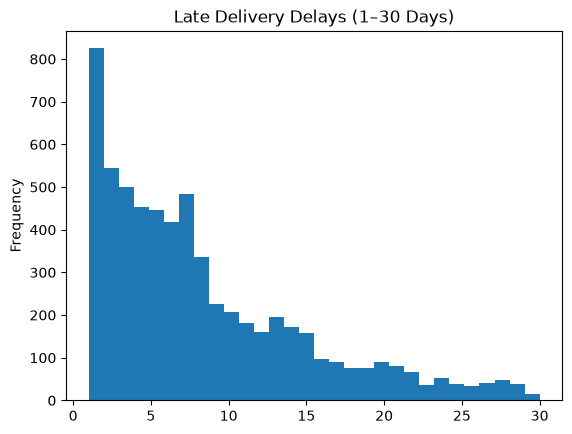

In [32]:
orders.loc[
    (orders["delivery_delay_days"] > 0) &
    (orders["delivery_delay_days"] <= 30),
    "delivery_delay_days"
].plot.hist(bins=30, title="Late Delivery Delays (1–30 Days)")

In [33]:
monthly_orders = (
    orders.groupby(
        orders["order_purchase_timestamp"].dt.to_period("M")
    )["order_id"].count()
)

monthly_orders

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: order_id, dtype: int64

<Axes: title={'center': 'Monthly Order Trends'}, xlabel='order_purchase_timestamp'>

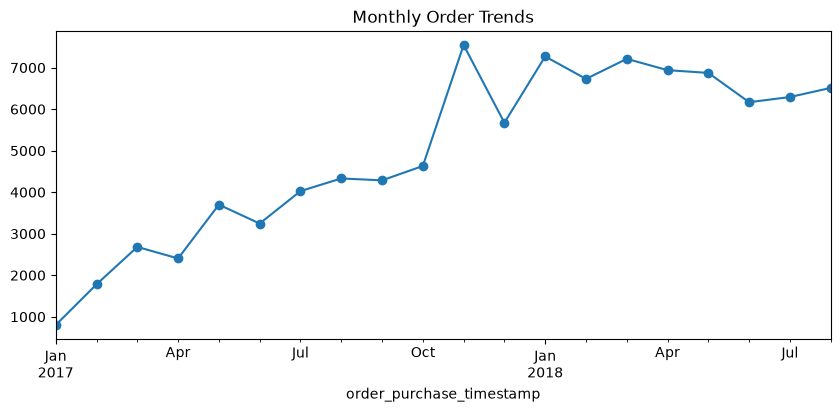

In [34]:
monthly_orders.loc["2017-01":"2018-08"].plot(
    kind="line",
    marker="o",
    figsize=(10, 4),
    title="Monthly Order Trends"
)

In [35]:
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [36]:
order_items.shape

(112650, 7)

In [37]:
order_items.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [38]:
order_items.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [39]:
order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [40]:
(order_items[["price", "freight_value"]] < 0).sum()

price            0
freight_value    0
dtype: int64

In [41]:
(order_items[["price", "freight_value"]] < 0).sum()

price            0
freight_value    0
dtype: int64

In [42]:
order_items["item_total"] = (
    order_items["price"] + order_items["freight_value"]
)

In [43]:
order_items[["price", "freight_value", "item_total"]].head()

,price,freight_value,item_total
0,58.90,13.29,72.19
1,239.90,19.93,259.83
2,199.00,17.87,216.87
3,12.99,12.79,25.78
4,199.90,18.14,218.04


In [45]:
order_totals = (
    order_items.groupby("order_id")["item_total"]
    .sum()
    .reset_index()
)

order_totals.head()

,order_id,item_total
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [46]:
order_totals = (
    order_items.groupby("order_id")["item_total"]
    .sum()
    .reset_index()
)

order_totals.head()

,order_id,item_total
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [47]:
orders_with_totals = orders.merge(
    order_totals,
    on="order_id",
    how="left"
)

orders_with_totals.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_delay_days,item_total
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,-13.0,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,-10.0,28.62


In [48]:
orders_with_totals["item_total"].isna().sum()

np.int64(775)

In [49]:
orders_with_totals.loc[
    orders_with_totals["item_total"].isna(),
    "order_status"
].value_counts()

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [50]:
monthly_sales = (
    orders_with_totals.dropna(subset=["item_total"])
    .groupby(
        orders_with_totals["order_purchase_timestamp"].dt.to_period("M")
    )["item_total"]
    .sum()
)

monthly_sales

order_purchase_timestamp
2016-09        354.75
2016-10      56808.84
2016-12         19.62
2017-01     137188.49
2017-02     286280.62
2017-03     432048.59
2017-04     412422.24
2017-05     586190.95
2017-06     502963.04
2017-07     584971.62
2017-08     668204.60
2017-09     720398.91
2017-10     769312.37
2017-11    1179143.77
2017-12     863547.23
2018-01    1107301.89
2018-02     986908.96
2018-03    1155126.82
2018-04    1159698.04
2018-05    1149781.82
2018-06    1022677.11
2018-07    1058728.03
2018-08    1003308.47
2018-09        166.46
Freq: M, Name: item_total, dtype: float64

<Axes: title={'center': 'Monthly Order Value'}, xlabel='order_purchase_timestamp'>

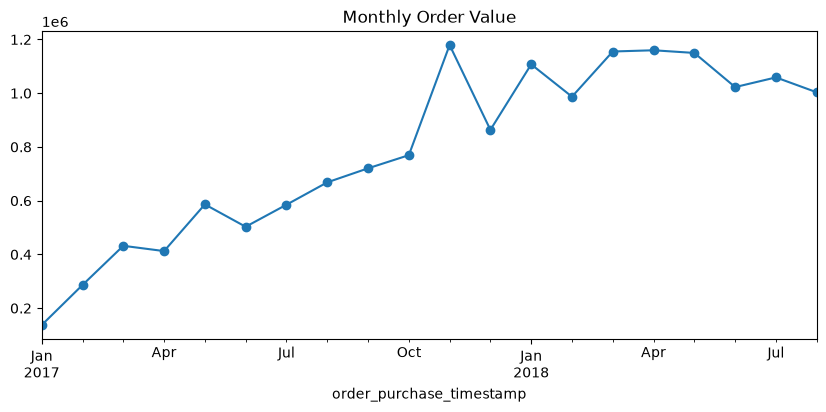

In [51]:
monthly_sales.loc["2017-01":"2018-08"].plot(
    kind="line",
    marker="o",
    figsize=(10, 4),
    title="Monthly Order Value"
)

## Key Findings

- Average delivery time was about 12 days, with a median of 10 days.
- About 6.8% of orders with delivery information arrived later than their estimated delivery date.
- Among late orders, the median delay was 7 days, although a small number experienced much longer delays.
- Monthly order volume grew strongly during 2017 and remained relatively stable through most of 2018.
- Monthly order value followed a similar pattern, reaching around 1 million or more during several months in 2018.
- The very small number of orders near the end of the dataset suggests that the final months may contain incomplete data.